In [113]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import center_of_mass, shift, rotate
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from pca import CustomPCA  # Your custom PCA implementation
from kmeans import MyKMeans  # Make sure your MyKMeans is saved here


In [114]:
# Load image dataset and true digit labels
X_modified = np.load("X_modified.npy")  # Shape: (1000, 28, 28)
y_true = np.load("y_true.npy")          # Shape: (1000,)


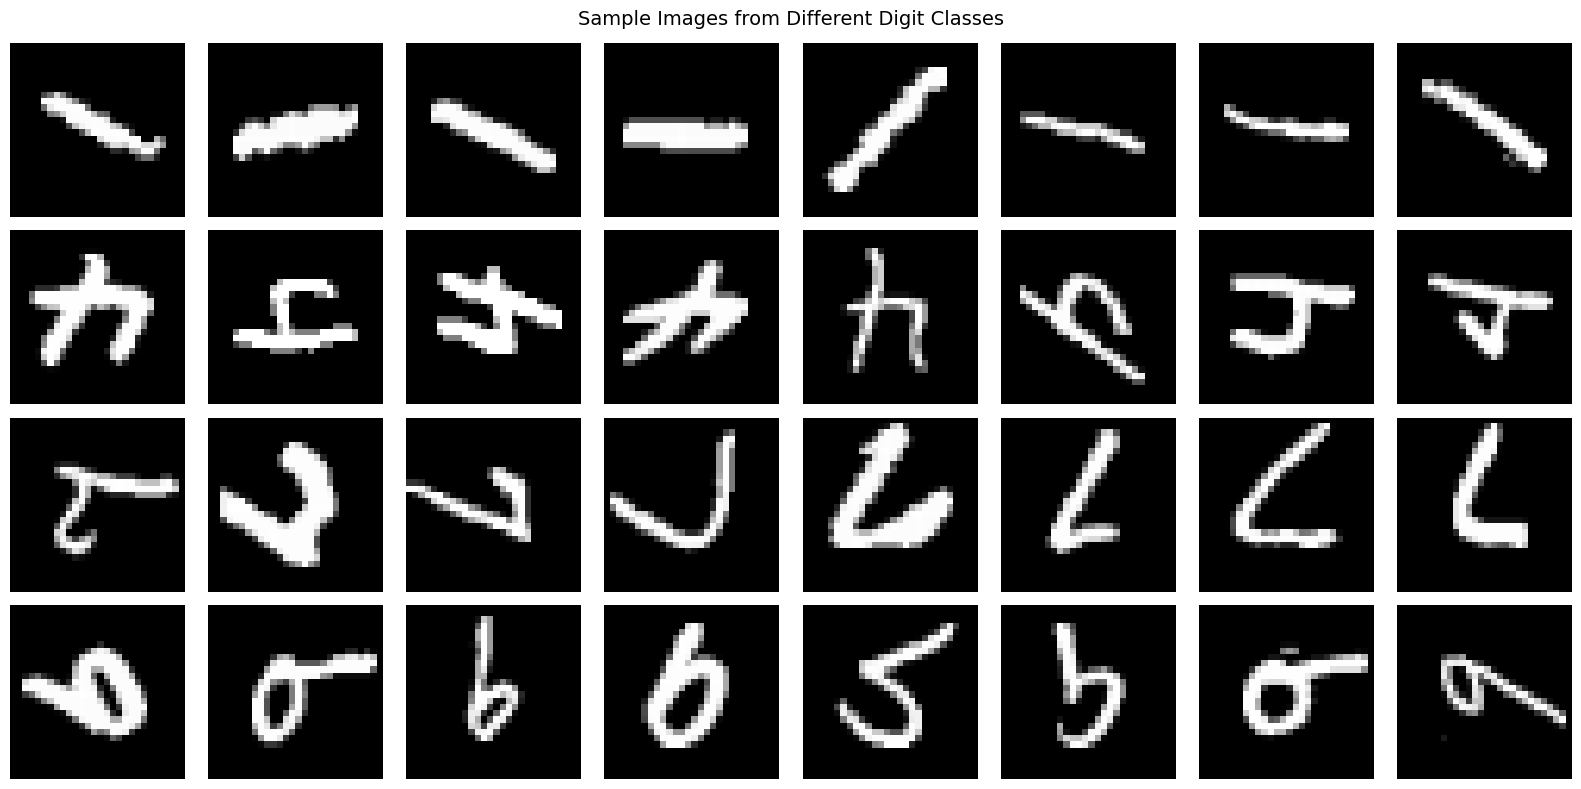

In [115]:
def show_images_by_digit(X, y, digits=[1, 4, 7 , 9], samples_per_digit=10):
    """
    Display a few sample images for selected digits.
    """
    rows = len(digits)
    cols = samples_per_digit
    plt.figure(figsize=(2 * cols, 2 * rows))

    for row, digit in enumerate(digits):
        digit_indices = np.where(y == digit)[0]
        if len(digit_indices) < samples_per_digit:
            print(f"Not enough samples for digit {digit}. Skipping.")
            continue

        chosen = np.random.choice(digit_indices, samples_per_digit, replace=False)

        for col in range(samples_per_digit):
            idx = row * cols + col + 1
            plt.subplot(rows, cols, idx)
            plt.imshow(X[chosen[col]], cmap='gray')
            if col == 0:
                plt.ylabel(f"Digit {digit}", fontsize=12)
            plt.axis('off')

    plt.suptitle("Sample Images from Different Digit Classes", fontsize=14)
    plt.tight_layout()
    plt.show()

# Call the visualization function
show_images_by_digit(X_modified, y_true, digits=[1, 4, 7, 9], samples_per_digit=8)


In [116]:
def preprocess_image(img):
    """
    Preprocess an image by aligning its principal axis and centering it.
    """
    binary_img = img > 0.1
    coords = np.column_stack(np.where(binary_img))

    if len(coords) < 2:
        return img  # Skip if image is too empty

    # PCA orientation
    cov = np.cov(coords.T)
    eigvals, eigvecs = np.linalg.eigh(cov)
    angle = np.arctan2(*eigvecs[:, 0][::-1])
    angle_deg = np.rad2deg(angle)
    rotated_img = rotate(img, angle=-angle_deg, reshape=False, mode='constant')

    # Centering
    cy, cx = center_of_mass(rotated_img)
    sy, sx = np.array(rotated_img.shape) // 2 - np.array([cy, cx])
    centered_img = shift(rotated_img, shift=(sy, sx), mode='constant')

    return centered_img


In [117]:
from scipy.stats import mode

def purity_score(y_true, y_pred):
    # Compute contingency matrix (confusion matrix)
    labels = np.unique(y_pred)
    total = 0
    for label in labels:
        # Select all samples with the current predicted label
        mask = y_pred == label
        true_labels = y_true[mask]
        if len(true_labels) == 0:
            continue
        # Count the most frequent true label in this cluster
        most_common = mode(true_labels, keepdims=True)[0][0]
        count = np.sum(true_labels == most_common)
        total += count
    return total / len(y_true)


In [118]:
# Apply the preprocessing to all images
X_rotated_centered = np.array([preprocess_image(img) for img in X_modified])

# Flatten images for PCA input
X_flat = X_modified.reshape(1000, -1)
X_processed_flat = X_rotated_centered.reshape(1000, -1)


In [119]:


# from skimage.feature import hog

# def extract_hog_features(X, pixels_per_cell=(7, 7), cells_per_block=(2, 2), orientations=9):
#     """
#     Extract HOG features for all images in X (X shape: (n_samples, H, W)).
#     Returns array shape (n_samples, n_features).
#     """
#     hog_feats = []
#     for img in X:
#         # ensure float image in range [0,1]
#         imgf = img.astype(float)
#         feats = hog(imgf,
#                     orientations=orientations,
#                     pixels_per_cell=pixels_per_cell,
#                     cells_per_block=cells_per_block,
#                     block_norm='L2-Hys',
#                     visualize=False,
#                     feature_vector=True,
#                     channel_axis=None)
#         hog_feats.append(feats)
#     return np.array(hog_feats)

# # Extract HOG features before and after preprocessing
# X_hog_before = extract_hog_features(X_modified)
# X_hog_after  = extract_hog_features(X_rotated_centered)

# # Reduce HOG dimensionality with PCA (tune n_components as needed)
# pca_hog_before = CustomPCA(n_components=30)
# pca_hog_before.fit(X_hog_before)
# X_hog_pca_before = pca_hog_before.transform(X_hog_before)

# pca_hog_after = CustomPCA(n_components=30)
# pca_hog_after.fit(X_hog_after)
# X_hog_pca_after = pca_hog_after.transform(X_hog_after)

# # KMeans on HOG features
# kmeans_hog_before = MyKMeans(k=10, max_iters=100, random_state=42)
# kmeans_hog_before.fit(X_hog_pca_before)
# labels_hog_before = kmeans_hog_before.labels_
# ari_hog_before = adjusted_rand_score(y_true, labels_hog_before)
# nmi_hog_before = normalized_mutual_info_score(y_true, labels_hog_before)
# purity_hog_before = purity_score(y_true, labels_hog_before)

# kmeans_hog_after = MyKMeans(k=10, max_iters=100, random_state=42)
# kmeans_hog_after.fit(X_hog_pca_after)
# labels_hog_after = kmeans_hog_after.labels_
# ari_hog_after = adjusted_rand_score(y_true, labels_hog_after)
# nmi_hog_after = normalized_mutual_info_score(y_true, labels_hog_after)
# purity_hog_after = purity_score(y_true, labels_hog_after)

# print("=== HOG + PCA + KMeans Evaluation ===")
# print(f"ARI  HOG Before: {ari_hog_before:.4f}")
# print(f"NMI  HOG Before: {nmi_hog_before:.4f}")
# print(f"Purity HOG Before: {purity_hog_before:.4f}")
# print(f"ARI  HOG After : {ari_hog_after:.4f}")
# print(f"NMI  HOG After : {nmi_hog_after:.4f}")
# print(f"Purity HOG After : {purity_hog_after:.4f}")

# # Quick bar plot comparing HOG results
# metrics_hog = ['ARI', 'NMI', 'Purity']
# before_hog_scores = [ari_hog_before, nmi_hog_before, purity_hog_before]
# after_hog_scores  = [ari_hog_after, nmi_hog_after, purity_hog_after]

# x = np.arange(len(metrics_hog))
# width = 0.35
# plt.figure(figsize=(8,4))
# plt.bar(x - width/2, before_hog_scores, width, label='HOG Before', color='coral')
# plt.bar(x + width/2, after_hog_scores, width, label='HOG After', color='seagreen')
# for i, v in enumerate(before_hog_scores):
#     plt.text(i - width/2, v + 0.01, f"{v:.2f}", ha='center')
# for i, v in enumerate(after_hog_scores):
#     plt.text(i + width/2, v + 0.01, f"{v:.2f}", ha='center')
# plt.ylim(0,1)
# plt.xticks(x, metrics_hog)
# plt.title('HOG: Clustering Performance Before vs After Preprocessing')
# plt.legend()
# plt.grid(axis='y', linestyle='--', alpha=0.6)
# plt.tight_layout()
# plt.show()



In [120]:
# PCA before preprocessing
pca = CustomPCA(n_components=50)
pca.fit(X_flat)
X_pca_before = pca.transform(X_flat)

# PCA after preprocessing
pca_processed = CustomPCA(n_components=50)
pca_processed.fit(X_processed_flat)
X_pca_after = pca_processed.transform(X_processed_flat)


In [121]:
# Clustering BEFORE preprocessing
kmeans_before = MyKMeans(k=10, max_iters=100, random_state=42)
kmeans_before.fit(X_pca_before)
labels_before = kmeans_before.labels_
ari_before = adjusted_rand_score(y_true, labels_before)
nmi_before = normalized_mutual_info_score(y_true, labels_before)
purity_before = purity_score(y_true, labels_before)

# Clustering AFTER preprocessing
kmeans_after = MyKMeans(k=10, max_iters=100, random_state=42)
kmeans_after.fit(X_pca_after)
labels_after = kmeans_after.labels_
ari_after = adjusted_rand_score(y_true, labels_after)
nmi_after = normalized_mutual_info_score(y_true, labels_after)
purity_after = purity_score(y_true, labels_after)
# purity_before = purity_score(y_true, labels_before)



In [122]:
#  Print comparison results
print("=== Clustering Evaluation ===")
print(f"ARI  Before: {ari_before:.4f}")
print(f"NMI  Before: {nmi_before:.4f}")
print(f"Purity Before: {purity_before:.4f}")


print(f"ARI  After : {ari_after:.4f}")
print(f"NMI  After : {nmi_after:.4f}")
print(f"Purity After : {purity_after:.4f}")


=== Clustering Evaluation ===
ARI  Before: 0.1900
NMI  Before: 0.2548
Purity Before: 0.5630
ARI  After : 0.3588
NMI  After : 0.3666
Purity After : 0.6800


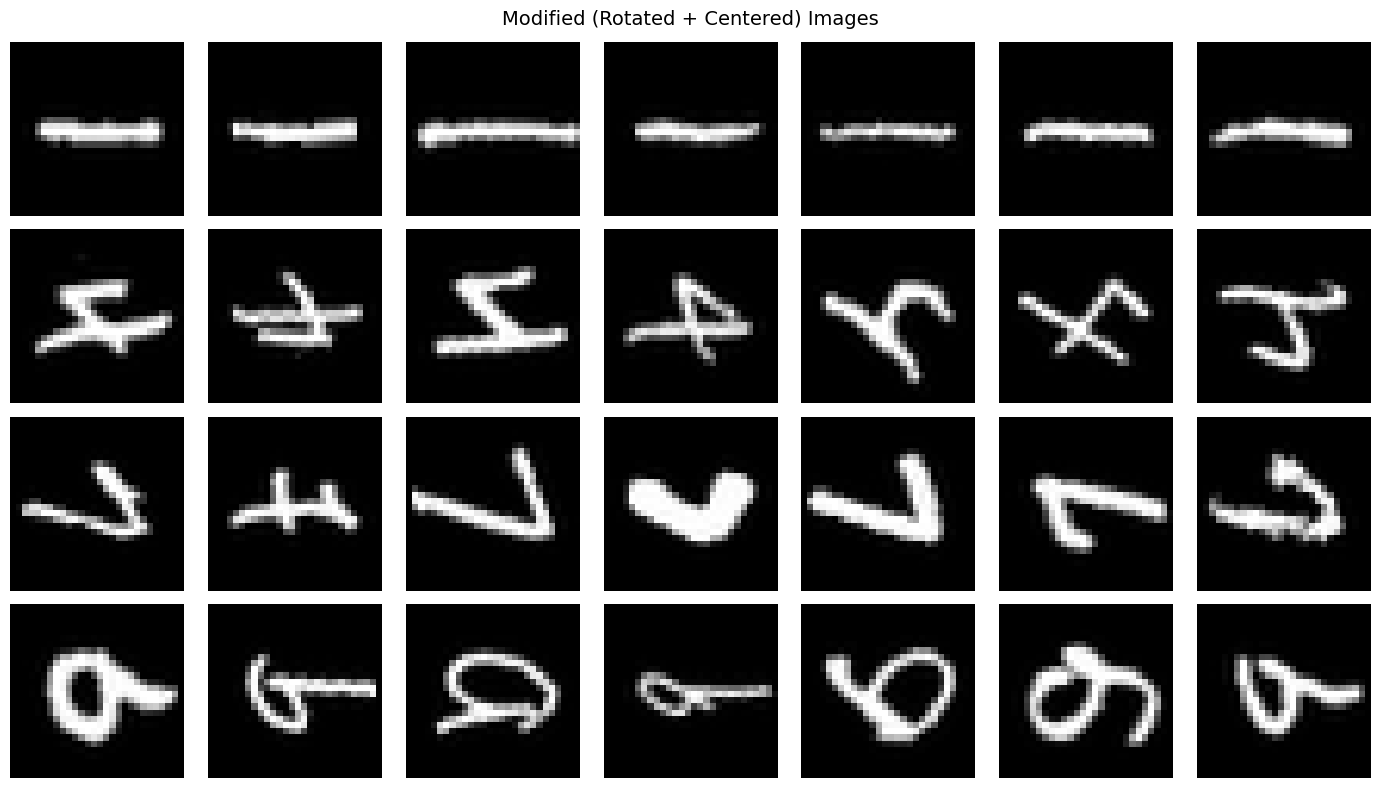

In [123]:


def show_modified_images(X_modified, y, digits=[1, 4,7,9], samples_per_digit=4):
    rows = len(digits)
    cols = samples_per_digit
    plt.figure(figsize=(2 * cols, 2 * rows))

    for row, digit in enumerate(digits):
        digit_indices = np.where(y == digit)[0]
        if len(digit_indices) < samples_per_digit:
            print(f"Not enough samples for digit {digit}. Skipping.")
            continue

        chosen = np.random.choice(digit_indices, samples_per_digit, replace=False)

        for col in range(samples_per_digit):
            idx = row * cols + col + 1
            plt.subplot(rows, cols, idx)
            plt.imshow(X_modified[chosen[col]], cmap='gray')
            if col == 0:
                plt.ylabel(f"Digit {digit}", fontsize=12)
            plt.axis('off')

    plt.suptitle("Modified (Rotated + Centered) Images", fontsize=14)
    plt.tight_layout()
    plt.show()


# Show modified images for 2 digits
show_modified_images(X_rotated_centered, y_true, digits=[1, 4 , 7,9], samples_per_digit=7)
    

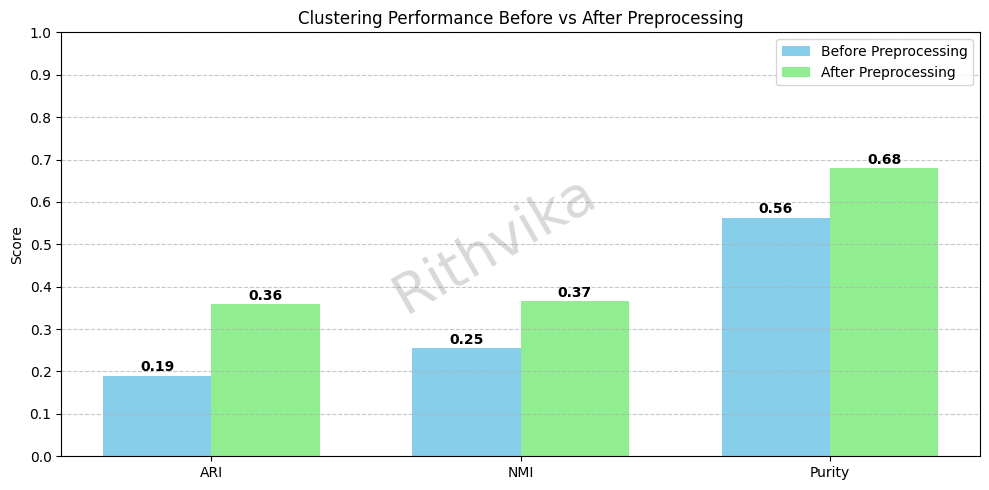

In [124]:

metrics = ['ARI', 'NMI', 'Purity']
before_scores = [ari_before, nmi_before, purity_before]
after_scores = [ari_after, nmi_after, purity_after]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))
bars1 = plt.bar(x - width/2, before_scores, width, label='Before Preprocessing', color='skyblue')
bars2 = plt.bar(x + width/2, after_scores, width, label='After Preprocessing', color='lightgreen')

# Add score labels on bars
for bar in bars1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.2f}", ha='center', fontweight='bold')

for bar in bars2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.2f}", ha='center', fontweight='bold')

# Configure plot aesthetics
plt.ylabel('Score')
plt.ylim(0, 1)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.title('Clustering Performance Before vs After Preprocessing')
plt.xticks(x, metrics)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.text(0.5, 0.5, 'Rithvika',
         transform=plt.gcf().transFigure,
         fontsize=40, color='gray', alpha=0.3,
         ha='center', va='center', rotation=30)
plt.tight_layout()
plt.show()


<!-- 1. Observed Differences Between the Modified Dataset and Standard MNIST (4 marks)

When comparing the modified dataset to the original MNIST dataset, several differences can be noticed:

Rotation: The digits in the modified dataset are often tilted at various angles. In contrast, MNIST digits are upright and well-aligned.

Not Centered: In the standard MNIST dataset, digits are usually centered in the image. But in the modified version, many digits appear shifted to one side or corner.

Shape Distortion: Some digits appear stretched or compressed because of the rotation and shifting, which changes their overall appearance slightly.

Increased Variation Within Each Class: Due to all these distortions, digits from the same class (e.g., all '4's) look more different from each other than they normally would. This makes it harder for clustering algorithms to group them correctly.

These issues cause problems for clustering because algorithms like KMeans group data based on similarity — and here, the same digits don’t look very similar anymore due to rotation and misalignment. -->

## 7. Enhancing Clustering Accuracy with Data Transformation  

### 1. Observed Differences Between the Modified Dataset and Standard MNIST 

When comparing the modified dataset to the original MNIST dataset, several differences can be noticed:  

- **Rotation**:  
  In the modified dataset, digits are often rotated at random angles (slightly tilted or even significantly slanted).  
  - In MNIST, digits are consistently upright, which preserves a uniform orientation across the dataset.  
  - Rotation introduces variability that makes digits of the same class (e.g., '7') look very different depending on their angle.  

- **Not Centered / Misalignment**:  
  Standard MNIST digits are carefully centered within the 28×28 image frame. This ensures each digit is positioned consistently across samples.  
  - In the modified dataset, digits are frequently shifted to one side, moved up or down, or placed in a corner.  
  - This misalignment breaks the spatial consistency, so clustering algorithms that rely on pixel positions struggle to recognize similar patterns.  

- **Shape Distortion**:  
  Some digits appear stretched or compressed due to the rotation and shifting process. This changes their proportions, making the digit structure less uniform.  

- **Increased Variation Within Each Class**:  
  These combined distortions (rotation, misalignment, stretching) mean that digits from the same class (e.g., all *1s* or *4s*) show much greater intra-class variation.  
  - In MNIST, a class cluster is relatively compact, but here, the class clusters become spread out and harder to distinguish.  

- As a result, clustering algorithms like **KMeans**, which depend on similarity in pixel patterns, face challenges: digits of the same class may not look alike due to differences in orientation and alignment, reducing clustering accuracy.  




### 2. Transformation Technique Used and Why It Works   

To fix the issues in the modified dataset, I applied a transformation that includes two main steps:  

---

**Step 1: Rotation Correction (Orientation Alignment)**  

- **How it works**:  
  - I detect the direction the digit is “pointing” by applying **Principal Component Analysis (PCA)** to the set of pixel coordinates where the digit is present.  
  - PCA finds the **principal axis of variation** in the digit (e.g., the longest direction of the stroke).  
  - Using this axis, I compute the rotation angle and rotate the digit so that its main axis becomes vertical, making the digit upright.  

- **Why it helps**:  
  - Many digits in the modified dataset were tilted. Aligning them in one direction makes all samples more consistent.  
  - For example, a slanted “7” will look closer to a standard upright “7,” which reduces unnecessary variation.  

---

**Step 2: Centering (Translation Adjustment)**  

- **How it works**:  
  - After rotation, I calculate the **center of mass** of the digit’s pixels.  
  - I then shift the image so that this center aligns with the center of the frame.  
  - This ensures the digit is not off to the side or corner, but placed consistently in the middle, just like in MNIST.  

- **Why it helps**:  
  - In clustering, pixel positions matter. If digits are in different corners, algorithms see them as different even if the shapes are the same.  
  - Centering eliminates this source of variation, so digits of the same class overlap more closely in feature space.  

---

**Why this works overall**  

- By **rotating and centering**, each digit is normalized to have:  
  1. A consistent orientation .  
  2. A consistent position (centered).  
- This transformation removes distortions caused by random rotations and shifts in the modified dataset.  
- As a result:  
  - **Clustering algorithms (like KMeans)** can focus on the *true shape* of the digits instead of being confused by position or tilt.  
  - Intra-class variation is reduced, making clusters tighter and easier to separate.  

---


### 3. Clustering Performance: Before vs After Transformation 

To test how well this transformation helps, I applied clustering before and after the preprocessing using **KMeans**.  
I evaluated performance using three metrics:  

- **ARI (Adjusted Rand Index)**: Measures how well the predicted clusters match the true labels.  
- **NMI (Normalized Mutual Information)**: Measures how much information the clusters share with the true labels.  
- **Purity**: Measures the extent to which clusters contain a single class (higher is better).  

---

**🔍 Results:**

| Metric  | Before Preprocessing | After Preprocessing |
|---------|-------------------|------------------|
| ARI     | 0.1900            | 0.3588           |
| NMI     | 0.2548            | 0.3666           |
| Purity  | 0.5630            | 0.6800           |

---

**What this shows:**  

- **ARI almost doubled**, meaning the clusters after transformation match the real digit labels much more closely.  
- **NMI increased**, indicating that the clustering captures more accurate information about the true labels.  
- **Purity improved**, showing that clusters now contain more consistent digits of the same class.  
- **Visual inspection** confirms that digits are more upright and centered, aligning with the improved evaluation scores.  


### 4. Why the Transformation Improved Clustering 

The transformation helped clustering for several reasons:  

- **Rotation Alignment**:  
  - By rotating digits upright, we reduce unnecessary variation caused by angles.  
  - Digits like "1" or "7" now look more similar across samples, making clusters tighter.  

- **Centering**:  
  - Centering ensures each digit is positioned consistently in the image frame.  
  - This prevents the model from being misled by variations in placement.  

- **More Consistent Features**:  
  - Rotation and centering make the shapes of digits more consistent across the dataset.  
  - KMeans can now group digits based on their true shape rather than their position or tilt.  

- **Better Feature Extraction**:  
  - When PCA is applied after preprocessing, it focuses on the actual shape of the digit.  
  - Irrelevant variations, such as rotation or shift, no longer dominate the feature space.  

---

**Final Thoughts**  

This preprocessing step rotating and centering digits significantly improved clustering.  
It reduced noise and variability, allowing clustering algorithms to focus on important features (digit shapes), which led to much better performance.  


<!-- 2. Transformation Technique Used and Why It Works (6 marks)

To fix the issues in the modified dataset, I applied a transformation that includes two main steps:

✅ Step 1: Rotation Correction

First, I detect the direction the digit is “pointing” by calculating the direction of its shape using PCA (Principal Component Analysis).

Then, I rotate the digit so that it becomes upright, just like in the standard MNIST images.

✅ Step 2: Centering

After rotation, I calculate the center of the digit (its center of mass).

Then, I shift the image so that the digit is right in the middle of the image frame.

✅ Why this works:

By rotating and centering each image, all digits are now better aligned and placed similarly, just like in the standard MNIST dataset.

This makes it easier for clustering algorithms to recognize digits based on their true shape rather than being confused by their position or angle.

This transformation helps reduce noise and makes the digits look more consistent across the dataset. -->

- We first observed that the modified digits were rotated and misaligned, causing high intra-class variation.  
To address this, each image was preprocessed by **aligning its principal axis using PCA** and then **centering it based on its center of mass**.  
After flattening and applying PCA for dimensionality reduction, KMeans clustering was performed before and after preprocessing.  
The transformation significantly improved clustering metrics (ARI, NMI, Purity) by making digits more consistent in orientation and position, allowing the algorithm to focus on their true shapes.
